<a href="https://colab.research.google.com/github/amsalu2212/Project/blob/main/DIgital%20Image%20Processing_Piecewise-linear%20brightness%20transformation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
DIPQ2

# **Name: Amsalu Tessema Adgeh**
#**ID Number: 2026A8000929002**
# **Digital Image processing Assignment-1**

#**Problem 2 — Piecewise Linear Brightness Transformation**

2)Using piecewise linear functions for brightness transformation is an effective and
versatile method for image enhancement. We usually select some control points, and
adjacent control points can determine a mapping line within the corresponding interval.
When the slope of this line, k, is equal to 1, k is greater than 1, or 0 < k < 1, what kind
of image processing effects can be achieved? Additionally, please further discuss and
consider the case when k < 0.


### **ANSWER**:

In piecewise linear transformation, the input range \([0, L-1]\) is divided by control points. Within each interval, a line with slope \(k\) maps input \(r\) to output \(s\).

| Slope \(k\) | Effect | Explanation |
|:---:|---|---|
| **\(k = 1\)** | Identity in that interval | Output = Input, no contrast or brightness change |
| **\(k > 1\)** | Contrast stretching | Dynamic range in that interval widened; detail more visible; may clip |
| **\(0 < k < 1\)** | Contrast compression | Dynamic range squeezed; less detail; suppresses noise |
| **\(k < 0\)** | Intensity inversion | Bright ↔ Dark reversed in that interval; produces a partial negative |

#### Discussion of \(k < 0\)

- The mapping reverses gray levels inside that interval.
- \(|k| = 1\) → full inversion, when the interval endpoints are mapped accordingly.
- \(|k| > 1\) → steep inversion, may clip.
- \(0 < |k| < 1\) → soft inversion, compresses the inverted range.
- Applications: digital negatives, highlighting anomalies in medical/scientific images, artistic effects.

#### Typical 3-segment contrast enhancement

- Dark region → \(k > 1\) (stretch shadows)
- Mid region → \(k \approx 1\) (preserve midtones)
- Bright region → \(k > 1\) (stretch highlights)

#GENERALLY,


DISCUSSION OF PIECEWISE LINEAR BRIGHTNESS TRANSFORMATION

1. k = 1: Identity transformation; input intensities remain unchanged.
2. k > 1: Contrast stretching; expands the intensity range.
3. 0 < k < 1: Contrast compression; reduces the intensity range.
4. k < 0: Intensity inversion; reverses brightness relationships in the interval.
5. k = -1 over [0,255]: Complete grayscale negative, s = 255 - r.

Applications:
- Enhancing selected intensity regions.
- Improving visibility of medical and scientific image features.
- Producing digital negatives and highlighting image details.

In [24]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage import data
import cv2

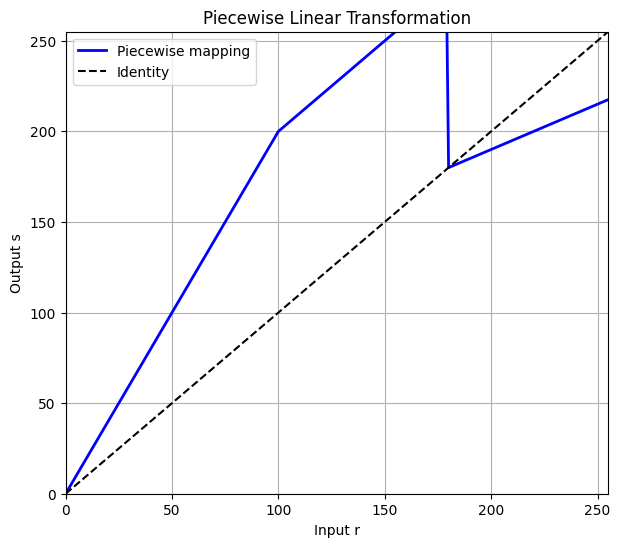

In [25]:
# Cell We can show the demonstration of piecewise linear mapping
r = np.arange(256, dtype=np.float32)
s = np.zeros_like(r)

# 3-segment mapping
s[r < 100]                = 2.0 * r[r < 100]                             # k = 2
s[(r >= 100) & (r < 180)] = 1.0 * r[(r >= 100) & (r < 180)] + 100       # k = 1
s[r >= 180]               = 0.5 * (r[r >= 180] - 180) + 180             # k = 0.5

plt.figure(figsize=(7, 6))
plt.plot(r, s, 'b-', linewidth=2, label='Piecewise mapping')
plt.plot([0,255],[0,255],'k--', label='Identity')
plt.grid(True); plt.legend()
plt.xlabel('Input r'); plt.ylabel('Output s')
plt.title('Piecewise Linear Transformation')
plt.xlim(0,255); plt.ylim(0,255)
plt.savefig('problem2_piecewise.png', dpi=150)
plt.show()

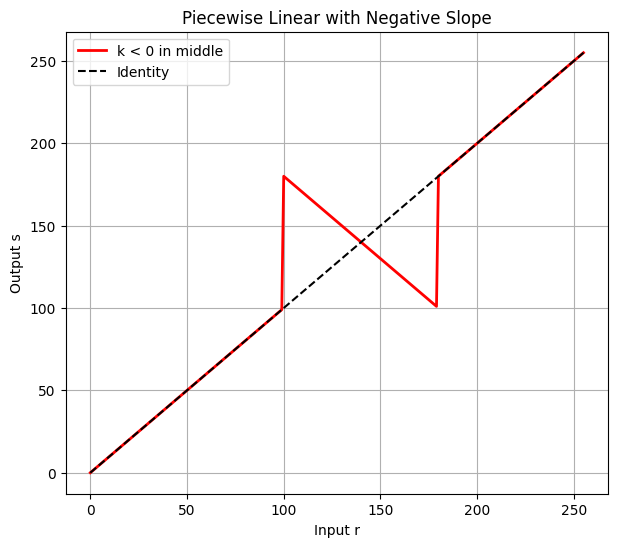

In [26]:
# We can also demonstrate the negative slope (partial inversion)
r = np.arange(256, dtype=np.float32)
s = np.zeros_like(r)

# Negative slope in [100, 180]
s[r < 100]                = r[r < 100]                                    # k=1
s[(r >= 100) & (r < 180)] = -1.0 * r[(r >= 100) & (r < 180)] + 280       # k=-1
s[r >= 180]               = r[r >= 180]                                   # k=1

plt.figure(figsize=(7, 6))
plt.plot(r, s, 'r-', linewidth=2, label='k < 0 in middle')
plt.plot([0,255],[0,255],'k--', label='Identity')
plt.grid(True); plt.legend()
plt.xlabel('Input r'); plt.ylabel('Output s')
plt.title('Piecewise Linear with Negative Slope')
plt.show()

In [27]:
def piecewise_linear(img, pts):
    """pts = [(r0,s0),(r1,s1),...] with increasing r; returns the uint8 mapped image."""
    pts = np.asarray(pts, dtype=float)
    lut = np.interp(np.arange(256), pts[:, 0], pts[:, 1])
    lut = np.clip(np.round(lut), 0, 255).astype(np.uint8)
    return lut[img]

Saving IMG_20260906_065222.jpg to IMG_20260906_065222.jpg
Image shape: (3488, 4640)
Data type: uint8
Min/Max pixel value: 0 255


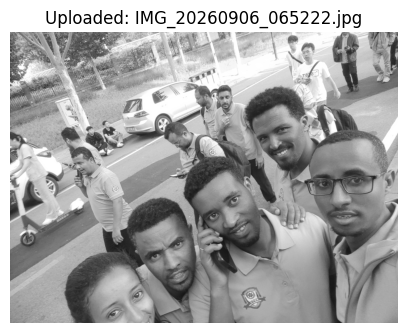

In [28]:
# First Upload our own image
from google.colab import files

uploaded = files.upload()          # a file-picker dialog appears
img_path = list(uploaded.keys())[0]
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

print("Image shape:", img.shape)
print("Data type:", img.dtype)
print("Min/Max pixel value:", img.min(), img.max())

plt.figure(figsize=(5,5))
plt.imshow(img, cmap='gray')
plt.title(f'Uploaded: {img_path}')
plt.axis('off')
plt.show()

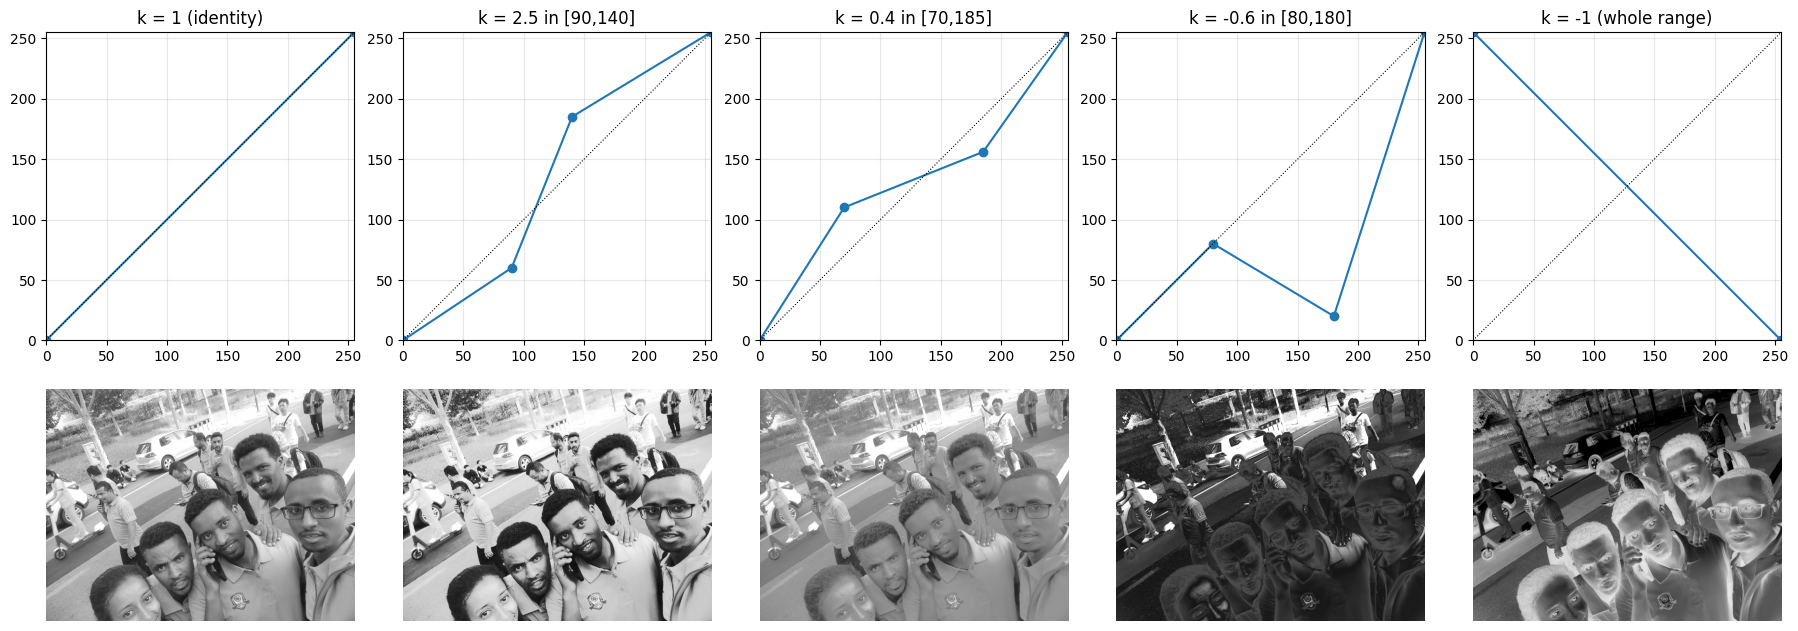

DISCUSSION OF PIECEWISE LINEAR BRIGHTNESS TRANSFORMATION

1. k = 1: Identity transformation; input intensities remain unchanged.
2. k > 1: Contrast stretching; expands the intensity range.
3. 0 < k < 1: Contrast compression; reduces the intensity range.
4. k < 0: Intensity inversion; reverses brightness relationships in the interval.
5. k = -1 over [0,255]: Complete grayscale negative, s = 255 - r.

Applications:
- Enhancing selected intensity regions.
- Improving visibility of medical and scientific image features.
- Producing digital negatives and highlighting image details.


In [29]:
cases = {
    "k = 1 (identity)":      [(0, 0), (255, 255)],
    "k = 2.5 in [90,140]":   [(0, 0), (90, 60), (140, 185), (255, 255)],
    "k = 0.4 in [70,185]":   [(0, 0), (70, 110), (185, 156), (255, 255)],
    "k = -0.6 in [80,180]":  [(0, 0), (80, 80), (180, 20), (255, 255)],
    "k = -1 (whole range)":  [(0, 255), (255, 0)],
}
fig, ax = plt.subplots(2, 5, figsize=(18, 6.8))
for i, (name, p) in enumerate(cases.items()):
    out = piecewise_linear(img, p); p = np.array(p)
    ax[0, i].plot(p[:, 0], p[:, 1], "o-"); ax[0, i].plot([0, 255], [0, 255], "k:", lw=.8)
    ax[0, i].set_xlim(0, 255); ax[0, i].set_ylim(0, 255); ax[0, i].set_aspect("equal")
    ax[0, i].set_title(name); ax[0, i].grid(alpha=.3)
    ax[1, i].imshow(out, cmap="gray", vmin=0, vmax=255); ax[1, i].axis("off")
plt.tight_layout(); plt.show()

print("DISCUSSION OF PIECEWISE LINEAR BRIGHTNESS TRANSFORMATION\n")
print("1. k = 1: Identity transformation; input intensities remain unchanged.")
print("2. k > 1: Contrast stretching; expands the intensity range.")
print("3. 0 < k < 1: Contrast compression; reduces the intensity range.")
print("4. k < 0: Intensity inversion; reverses brightness relationships in the interval.")
print("5. k = -1 over [0,255]: Complete grayscale negative, s = 255 - r.")

print("\nApplications:")
print("- Enhancing selected intensity regions.")
print("- Improving visibility of medical and scientific image features.")
print("- Producing digital negatives and highlighting image details.")